# TP 9 — Réseaux de neurones artificiels

**Cours :** *Artificial Neural Networks* (slides 215–242) — perceptron de **Rosenblatt** (descente de gradient stochastique, théorème de Rosenblatt-Novikoff, limites), **perceptron multicouche** (MLP), **rétropropagation du gradient**, théorème d'**approximation universelle**, **régularisation** (arrêt précoce, *dropout*, *weight decay*), **réseaux convolutifs** (expérience de LeCun 1989).

**À la fin de ce notebook, vous saurez :**
1. coder le perceptron et vérifier la borne de Novikoff sur le nombre de mises à jour ;
2. coder un MLP **from scratch** (propagation avant, rétropropagation) et **vérifier vos gradients** par différences finies — le réflexe n°1 de tout praticien ;
3. comparer arrêt précoce, *weight decay* et *dropout* ;
4. coder une **convolution** (et une couche localement connectée) et refaire l'expérience de LeCun : à nombre de données égal, le **partage de poids** gagne ;
5. confronter un MLP au modèle de référence **HAR** pour prévoir la volatilité du S&P 500.

> 📗 **Version corrigée.** Toutes les cellules s'exécutent de bout en bout.

In [1]:
import sys, pathlib, warnings
_here = pathlib.Path.cwd()
ROOT = _here.parent if _here.name in ("exercices", "corriges") else _here
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tp_utils import *          # style graphique, check(), check_close(), timer()...
import tp_data                  # données réelles (cache / téléchargement) ou simulées

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.precision", 4)
rng = np.random.default_rng(42)
from scipy.special import expit, logsumexp
from sklearn.datasets import load_digits
from sklearn.neural_network import MLPClassifier

## Partie 1 — Le perceptron de Rosenblatt (1957)

Classification binaire $y\in\{-1,1\}$, modèle $f(x) = \mathrm{sign}(\beta_0 + x^\top\beta)$. On minimise $D(\beta,\beta_0) = -\sum_{i\in\mathcal M}y_i(\beta_0 + x_i^\top\beta)$ sur l'ensemble $\mathcal M$ des points mal classés, par **descente de gradient stochastique** : pour chaque point mal classé, $\beta\leftarrow\beta + \varrho\,y_ix_i$, $\beta_0\leftarrow\beta_0 + \varrho\,y_i$.

**Théorème (Rosenblatt-Novikoff).** Si les données sont séparables avec une marge $\gamma$ (il existe $w^*$ unitaire avec $y_i\,w^{*\top}\tilde x_i\ge\gamma$, $\tilde x_i = (1, x_i)$) et $\|\tilde x_i\|\le R$, l'algorithme (avec $\varrho = 1$) s'arrête après **au plus $(R/\gamma)^2$ mises à jour**. S'il n'existe pas d'hyperplan séparateur, il ne converge pas.

### Exercice 1.1 — `perceptron`

In [2]:
def perceptron(X, y, rho=1.0, max_epochs=1000, seed=0):
    """Retourne (beta, beta0, nombre total de mises à jour, erreurs par époque)."""
    rr = np.random.default_rng(seed)
    n, d = X.shape
    beta, b0, updates, hist = np.zeros(d), 0.0, 0, []
    for epoch in range(max_epochs):
        mistakes = 0
        for i in rr.permutation(n):
            if y[i] * (b0 + X[i] @ beta) <= 0:
                beta += rho * y[i] * X[i]; b0 += rho * y[i]
                mistakes += 1; updates += 1
        hist.append(mistakes)
        if mistakes == 0:
            break
    return beta, b0, updates, hist

In [3]:
# Test : borne de Novikoff sur des données séparables de marge contrôlée
rows = []
w_star = np.array([0.3, 1.0, -1.0]); w_star /= np.linalg.norm(w_star)
for gamma in [0.3, 0.2, 0.1, 0.05, 0.02]:
    Xg = rng.uniform(-2, 2, (3000, 2)); Xt_ = np.c_[np.ones(len(Xg)), Xg]
    m = Xt_ @ w_star
    keep = np.abs(m) >= gamma
    Xg, yg = Xg[keep][:400], np.sign(m[keep])[:400]
    R = np.linalg.norm(np.c_[np.ones(len(Xg)), Xg], axis=1).max()
    _, _, upd, _ = perceptron(Xg, yg)
    rows.append((gamma, upd, (R / gamma) ** 2))
nov = pd.DataFrame(rows, columns=["marge γ", "mises à jour", "borne (R/γ)²"])
check((nov["mises à jour"] <= nov["borne (R/γ)²"]).all(), "nombre de mises à jour ≤ (R/γ)²")
nov

✅ nombre de mises à jour ≤ (R/γ)²


,marge γ,mises à jour,borne (R/γ)²
0,0.30,8,86.9928
1,0.20,9,213.4259
2,0.10,11,838.1337
3,0.05,21,3416.6751
4,0.02,95,20970.2820


**Lecture :** plus la marge est petite, plus la convergence est lente. Et si les classes ne sont pas séparables (par exemple le XOR), le nombre d'erreurs par époque ne tombe jamais à 0 — c'est la limite qui a contribué au premier « hiver de l'IA » (Minsky & Papert, 1969).

In [4]:
Xx = rng.uniform(-1, 1, (400, 2)); yx = np.where(Xx[:, 0] * Xx[:, 1] > 0, 1, -1)
_, _, _, hist_xor = perceptron(Xx, yx, max_epochs=50)
print("XOR — erreurs par époque (10 dernières) :", hist_xor[-10:])

XOR — erreurs par époque (10 dernières) : [198, 189, 201, 202, 206, 197, 179, 183, 202, 191]


## Partie 2 — Perceptron multicouche et rétropropagation

**Architecture** : couches entièrement connectées, $A^{(0)} = X$, $Z^{(l)} = A^{(l-1)}W^{(l)} + b^{(l)}$, $A^{(l)} = g(Z^{(l)})$ pour les couches cachées ($g$ = ReLU, tanh ou sigmoïde) ; la dernière couche produit des **scores** : *softmax* + entropie croisée en classification, identité + MSE en régression.

**Rétropropagation** (règle de la chaîne, de la sortie vers l'entrée) : avec $\delta^{(L)} = \partial\mathcal L/\partial Z^{(L)}$ ($= (P - Y)/n$ pour softmax + entropie croisée, $= 2(\hat y - y)/n$ pour la MSE),
$$\frac{\partial\mathcal L}{\partial W^{(l)}} = A^{(l-1)\top}\delta^{(l)},\quad \frac{\partial\mathcal L}{\partial b^{(l)}} = \mathbf 1^\top\delta^{(l)},\quad \delta^{(l-1)} = \big(\delta^{(l)}W^{(l)\top}\big)\odot g'(Z^{(l-1)}).$$
**Weight decay** : on ajoute $\lambda\sum_l\|W^{(l)}\|_F^2$ à la perte, donc $2\lambda W^{(l)}$ au gradient (c'est ridge pour réseaux de neurones).
**Dropout** : à l'apprentissage, chaque neurone caché est éteint avec probabilité $p$ ; on multiplie les activations par un masque $M/(1-p)$ (*inverted dropout*), et on rétropropage à travers le même masque. Rien à faire en prédiction.

### Exercice 2.1 — Propagation avant et arrière

In [5]:
ACT = {"relu": (lambda z: np.maximum(z, 0), lambda z, h: (z > 0).astype(float)),
       "tanh": (np.tanh, lambda z, h: 1 - h ** 2),
       "sigmoid": (expit, lambda z, h: h * (1 - h))}


def init_mlp(sizes, seed=0):
    rr = np.random.default_rng(seed)
    return [[rr.normal(0, np.sqrt(2 / a), (a, b)), np.zeros(b)] for a, b in zip(sizes[:-1], sizes[1:])]


def forward(params, X, act="relu", dropout=0.0, rng=None):
    """Retourne (sortie, cache). dropout > 0 seulement à l'apprentissage."""
    g = ACT[act][0]
    cache = {"A": [X], "Z": [], "H": [], "M": []}
    A = X
    for l, (W, b) in enumerate(params):
        Z = A @ W + b
        if l < len(params) - 1:
            H = g(Z)
            M = (rng.random(H.shape) >= dropout) / (1 - dropout) if dropout > 0 else None
            A = H * M if M is not None else H
        else:
            H, M, A = None, None, Z
        cache["Z"].append(Z); cache["H"].append(H); cache["M"].append(M); cache["A"].append(A)
    return A, cache


def loss_and_grads(params, X, Y, task="classification", act="relu", lam=0.0, dropout=0.0, rng=None):
    """Y : entiers (classification) ou réels (régression, forme (n, 1)). Retourne (perte, gradients)."""
    out, cache = forward(params, X, act, dropout, rng)
    n = len(X)
    if task == "classification":
        logp = out - logsumexp(out, axis=1, keepdims=True)
        loss = -logp[np.arange(n), Y].mean()
        delta = np.exp(logp); delta[np.arange(n), Y] -= 1; delta /= n
    else:
        loss = ((out - Y) ** 2).mean()
        delta = 2 * (out - Y) / (n * out.shape[1])
    loss += lam * sum((W ** 2).sum() for W, _ in params)
    grads = [None] * len(params)
    gprime = ACT[act][1]
    for l in range(len(params) - 1, -1, -1):
        W, b = params[l]
        grads[l] = [cache["A"][l].T @ delta + 2 * lam * W, delta.sum(0)]
        if l > 0:
            dA = delta @ W.T
            if cache["M"][l - 1] is not None:
                dA = dA * cache["M"][l - 1]
            delta = dA * gprime(cache["Z"][l - 1], cache["H"][l - 1])
    return loss, grads

### Exercice 2.2 — Vérification des gradients par différences finies

Pour chaque paramètre $\theta$ : $\frac{\partial\mathcal L}{\partial\theta}\approx\frac{\mathcal L(\theta+\epsilon)-\mathcal L(\theta-\epsilon)}{2\epsilon}$. On compare sur un petit réseau (sans dropout) via l'erreur relative $\frac{|g - g_{num}|}{\max(|g|, |g_{num}|, 10^{-8})}$ — elle doit être ≲ $10^{-6}$. **Faites-le pour tout nouveau modèle** : un gradient faux n'empêche pas l'entraînement de « tourner », il le rend juste mauvais.

In [6]:
def grad_check(params, X, Y, eps=1e-6, **kw):
    _, grads = loss_and_grads(params, X, Y, **kw)
    worst = 0.0
    for (W, b), (gW, gb) in zip(params, grads):
        for P, G in [(W, gW), (b, gb)]:
            for idx in np.ndindex(P.shape):
                old = P[idx]
                P[idx] = old + eps; lp, _ = loss_and_grads(params, X, Y, **kw)
                P[idx] = old - eps; lm, _ = loss_and_grads(params, X, Y, **kw)
                P[idx] = old
                num = (lp - lm) / (2 * eps)
                worst = max(worst, abs(num - G[idx]) / max(abs(num), abs(G[idx]), 1e-8))
    return worst

Xs = rng.normal(size=(15, 4))
for act in ["tanh", "sigmoid"]:
    p_ = init_mlp([4, 6, 5, 3], seed=1)
    err = grad_check(p_, Xs, rng.integers(0, 3, 15), act=act, lam=0.01)
    check(err < 1e-5, f"gradients classification ({act}) : erreur relative max {err:.1e}")
p_ = init_mlp([4, 5, 1], seed=2)
err = grad_check(p_, Xs, rng.normal(size=(15, 1)), task="regression", act="tanh", lam=0.01)
check(err < 1e-5, f"gradients régression : erreur relative max {err:.1e}")

✅ gradients classification (tanh) : erreur relative max 9.6e-08
✅ gradients classification (sigmoid) : erreur relative max 1.1e-07
✅ gradients régression : erreur relative max 8.1e-09


### Entraînement (fourni) : Adam + mini-lots + arrêt précoce

Pour se concentrer sur le modèle, l'optimiseur est fourni : **Adam** (descente de gradient stochastique avec moments adaptatifs, l'optimiseur par défaut en pratique), mini-lots, et **arrêt précoce** si un jeu de validation est fourni (on garde les paramètres de la meilleure époque).

In [7]:
import copy

def train(params, X, Y, task="classification", act="relu", lam=0.0, dropout=0.0, epochs=500, batch=64,
          lr=0.01, X_val=None, Y_val=None, patience=None, seed=0, grad_fn=None):
    rr = np.random.default_rng(seed)
    grad_fn = grad_fn or (lambda p, xb, yb: loss_and_grads(p, xb, yb, task, act, lam, dropout, rr))
    flat = lambda ps: [a for pair in ps for a in pair]
    m = [np.zeros_like(a) for a in flat(params)]; v = [np.zeros_like(a) for a in flat(params)]
    hist = {"train": [], "val": []}; best = (np.inf, copy.deepcopy(params), 0); t = 0
    for ep in range(epochs):
        for s in range(0, len(X), batch):
            idx = rr.permutation(len(X))[:batch] if batch < len(X) else np.arange(len(X))
            _, grads = grad_fn(params, X[idx], Y[idx])
            t += 1
            for k, (p, g) in enumerate(zip(flat(params), flat(grads))):
                m[k] = 0.9 * m[k] + 0.1 * g; v[k] = 0.999 * v[k] + 0.001 * g ** 2
                p -= lr * (m[k] / (1 - 0.9 ** t)) / (np.sqrt(v[k] / (1 - 0.999 ** t)) + 1e-8)
        hist["train"].append(grad_fn(params, X, Y)[0] if dropout == 0 else
                             loss_and_grads(params, X, Y, task, act, lam, 0.0)[0])
        if X_val is not None:
            out, _ = forward(params, X_val, act)
            vl = (-(out - logsumexp(out, axis=1, keepdims=True))[np.arange(len(X_val)), Y_val].mean()
                  if task == "classification" else ((out - Y_val) ** 2).mean())
            hist["val"].append(vl)
            if vl < best[0]:
                best = (vl, copy.deepcopy(params), ep)
            elif patience is not None and ep - best[2] > patience:
                break
    return (best[1] if X_val is not None and patience is not None else params), hist


def mlp_predict(params, X, act="relu"):
    return forward(params, X, act)[0].argmax(1)

In [8]:
# Test : un MLP à une couche cachée résout le XOR (impossible pour le perceptron)
yx01 = (yx > 0).astype(int)
p_xor, _ = train(init_mlp([2, 8, 2], seed=0), Xx, yx01, act="tanh", epochs=300, lr=0.02)
check(np.mean(mlp_predict(p_xor, Xx, "tanh") == yx01) > 0.97, "le MLP résout le XOR")
ours_vs_sk = MLPClassifier((8,), activation="tanh", max_iter=3000, random_state=0).fit(Xx, yx01).score(Xx, yx01)
print(f"(sklearn MLPClassifier sur le même problème : {ours_vs_sk:.3f})")

✅ le MLP résout le XOR


(sklearn MLPClassifier sur le même problème : 0.968)


### Expérience 2.3 — Approximation universelle

**Théorème** (Cybenko 1989, Hornik 1991) : un MLP à **une** couche cachée suffisamment large approche uniformément toute fonction continue sur un compact. Vérifions-le en régression 1D en augmentant la largeur.

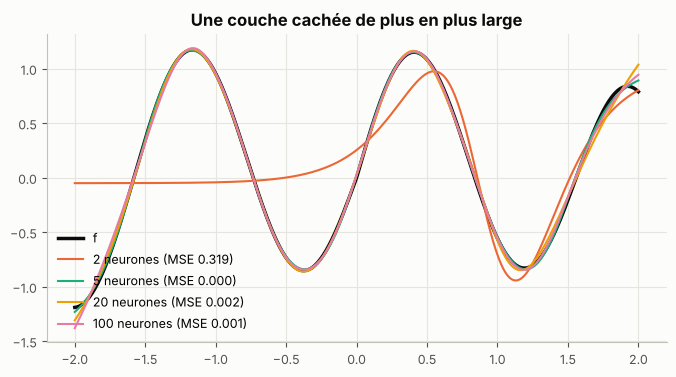

In [9]:
f_u = lambda x: np.sin(4 * x) + 0.5 * np.abs(x) - 0.3 * x ** 2
xu = np.linspace(-2, 2, 400)[:, None]; yu = f_u(xu)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(xu, yu, color=INK, lw=2.5, label="f")
for i, h in enumerate([2, 5, 20, 100]):
    p_u, _ = train(init_mlp([1, h, 1], seed=0), xu, yu, task="regression", act="tanh", epochs=1500, batch=400, lr=0.02)
    pred = forward(p_u, xu, "tanh")[0]
    ax.plot(xu, pred, color=PALETTE[i + 1], lw=1.5, label=f"{h} neurones (MSE {np.mean((pred - yu) ** 2):.3f})")
ax.set_title("Une couche cachée de plus en plus large"); ax.legend(); plt.show()

### Exercice 2.4 — Régularisation : arrêt précoce, weight decay, dropout

Jeu du cours (mélange de gaussiennes, $n = 200$, erreur de Bayes ≈ 21 %). On utilise volontairement un réseau **trop gros** (2 couches cachées de 64 neurones, ~4 600 paramètres pour 200 points) et on compare quatre stratégies. Pour l'arrêt précoce, on réserve 25 % de l'apprentissage comme validation.

✅ au moins une régularisation améliore la généralisation


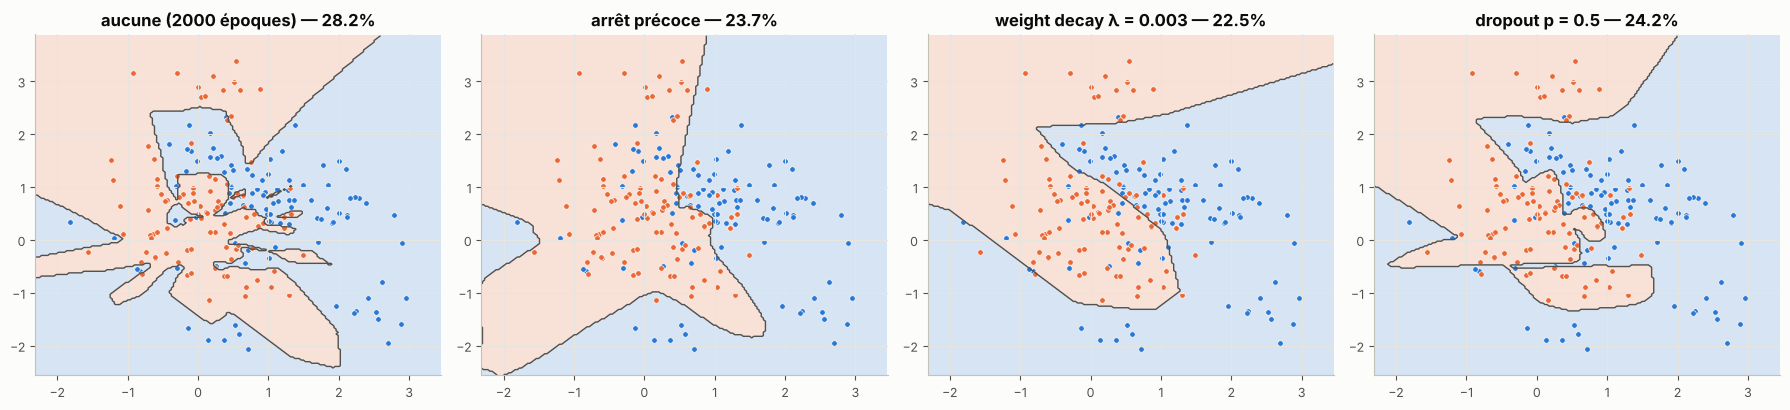

,erreur de test (%)
aucune (2000 époques),28.2
arrêt précoce,23.7
weight decay λ = 0.003,22.5
dropout p = 0.5,24.2


In [10]:
mix = tp_data.ESLMixture()
Xe, ye = mix.sample(100, seed=1)
Xt, yt = mix.sample(5000, seed=2)
perm = np.random.default_rng(0).permutation(200); itr, iva = perm[:150], perm[150:]
sizes = [2, 64, 64, 2]
results = {}
results["aucune (2000 époques)"] = train(init_mlp(sizes), Xe, ye, epochs=2000, lr=0.005)
results["arrêt précoce"] = train(init_mlp(sizes), Xe[itr], ye[itr], epochs=2000, lr=0.005,
                                 X_val=Xe[iva], Y_val=ye[iva], patience=200)
results["weight decay λ = 0.003"] = train(init_mlp(sizes), Xe, ye, epochs=2000, lr=0.005, lam=0.003)
results["dropout p = 0.5"] = train(init_mlp(sizes), Xe, ye, epochs=2000, lr=0.005, dropout=0.5)
tab = pd.Series({k: np.mean(mlp_predict(p, Xt) != yt) for k, (p, h) in results.items()}, name="erreur de test")
check(tab.drop("aucune (2000 époques)").min() < tab["aucune (2000 époques)"], "au moins une régularisation améliore la généralisation")

fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, (k, (p, h)) in zip(axes, results.items()):
    plot_decision_boundary(ax, lambda Z, p=p: mlp_predict(p, Z), Xe, ye, f"{k} — {tab[k]:.1%}")
plt.tight_layout(); plt.show()
(100 * tab).round(1).to_frame("erreur de test (%)")

## Partie 3 — Réseaux convolutifs : l'expérience de LeCun (1989)

LeCun compare sur des chiffres manuscrits ($16\times16$, 320 images d'apprentissage) des réseaux de complexité croissante : **Net-1** sans couche cachée, **Net-2** une couche cachée dense de 12 neurones, **Net-3** une couche cachée **localement connectée** (chaque neurone ne voit qu'un patch $3\times3$, poids propres), **Net-4** la même avec **poids partagés** (une **convolution**). Le partage de poids réduit le nombre de paramètres et encode l'**invariance par translation** — d'où une meilleure généralisation avec peu de données.

On refait l'expérience sur les chiffres $8\times8$ de scikit-learn (1797 images, aucun téléchargement), avec 320 images d'apprentissage. Ces chiffres étant centrés et très faciles, on retrouve la difficulté de l'expérience originale en les plaçant à une **position aléatoire** (décalage de 0 à 2 pixels) dans un cadre $10\times10$ : un modèle dense doit alors apprendre chaque motif à chaque position.

**Implémentation.** Avec l'opération `im2col`, qui extrait les $8\times8 = 64$ patchs $3\times3$ de chaque image $10\times10$ en un tableau `cols` de forme $(N, P, 9)$ avec $P = 64$ positions :
- **convolution** (poids partagés $W\in\mathbb R^{9\times F}$) : $\text{out}[n,p,f] = \sum_k \text{cols}[n,p,k]\,W[k,f] + b[f]$ ;
- **localement connecté** ($W\in\mathbb R^{P\times9\times F}$) : $\text{out}[n,p,f] = \sum_k \text{cols}[n,p,k]\,W[p,k,f] + b[p,f]$.

Comme ces couches sont les premières du réseau, on n'a pas besoin du gradient par rapport à l'entrée, seulement par rapport à $W$ et $b$ : $\partial\mathcal L/\partial W$ s'obtient en sommant `cols` × $\delta$ sur les indices non partagés. `np.einsum` rend tout cela très lisible.

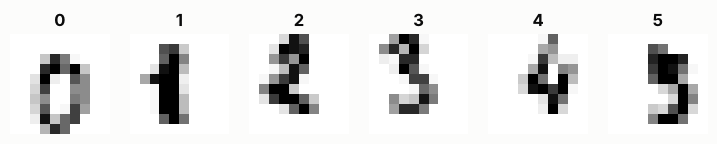

cols : (1797, 64, 9)


In [11]:
digits = load_digits()
yd = digits.target

def shifted_digits(seed, size=10):
    """Place chaque chiffre 8x8 à une position aléatoire dans un cadre size x size."""
    r_ = np.random.default_rng(seed)
    canvas = np.zeros((len(yd), size, size))
    off = r_.integers(0, size - 8 + 1, (len(yd), 2))
    for i, (a_, b_) in enumerate(off):
        canvas[i, a_:a_ + 8, b_:b_ + 8] = digits.images[i] / 16.0
    return canvas

def im2col(imgs, k=3):
    N, H, W_ = imgs.shape
    out = np.empty((N, (H - k + 1) * (W_ - k + 1), k * k))
    p = 0
    for i in range(H - k + 1):
        for j in range(W_ - k + 1):
            out[:, p] = imgs[:, i:i + k, j:j + k].reshape(N, -1); p += 1
    return out

imgs = shifted_digits(seed=0)
cols_all = im2col(imgs)                     # (1797, 64, 9)
fig, axes = plt.subplots(1, 6, figsize=(9, 1.8))
for ax, i in zip(axes, range(6)):
    ax.imshow(imgs[i], cmap="Greys"); ax.set_title(str(yd[i])); ax.axis("off")
plt.show()
print("cols :", cols_all.shape)

### Exercice 3.1 — Couches convolutive et localement connectée

In [12]:
def conv_forward(cols, W, b):
    return np.einsum("npk,kf->npf", cols, W) + b


def conv_backward(cols, delta):
    """delta = dL/d(out), forme (N, P, F). Retourne (dW, db)."""
    return np.einsum("npk,npf->kf", cols, delta), delta.sum((0, 1))


def local_forward(cols, W, b):
    return np.einsum("npk,pkf->npf", cols, W) + b


def local_backward(cols, delta):
    return np.einsum("npk,npf->pkf", cols, delta), delta.sum(0)

Le reste (fourni) assemble « couche cachée (conv ou locale) → tanh → couche dense → softmax », calcule perte et gradients, et réutilise `train` via l'argument `grad_fn`. Un contrôle de gradient valide vos deux couches. On moyenne ensuite les résultats sur 3 tirages (positions et découpage apprentissage/test).

In [13]:
def make_hidden_net(kind, P=64, F=4, seed=0):
    rr = np.random.default_rng(seed)
    Wh = rr.normal(0, 0.5, (9, F)) if kind == "conv" else rr.normal(0, 0.5, (P, 9, F))
    bh = np.zeros(F) if kind == "conv" else np.zeros((P, F))
    return [[Wh, bh], [rr.normal(0, np.sqrt(1 / (P * F)), (P * F, 10)), np.zeros(10)]]


def hidden_net_loss(kind, lam=1e-4):
    fwd, bwd = (conv_forward, conv_backward) if kind == "conv" else (local_forward, local_backward)
    def fn(params, cols, y):
        (Wh, bh), (Wo, bo) = params
        Hh = np.tanh(fwd(cols, Wh, bh)); N = len(cols)
        A = Hh.reshape(N, -1); out = A @ Wo + bo
        logp = out - logsumexp(out, axis=1, keepdims=True)
        loss = -logp[np.arange(N), y].mean() + lam * ((Wh ** 2).sum() + (Wo ** 2).sum())
        d = np.exp(logp); d[np.arange(N), y] -= 1; d /= N
        gWo, gbo = A.T @ d + 2 * lam * Wo, d.sum(0)
        dH = (d @ Wo.T).reshape(Hh.shape) * (1 - Hh ** 2)
        gWh, gbh = bwd(cols, dH)
        return loss, [[gWh + 2 * lam * Wh, gbh], [gWo, gbo]]
    return fn


def hidden_net_predict(kind, params, cols):
    fwd = conv_forward if kind == "conv" else local_forward
    (Wh, bh), (Wo, bo) = params
    return (np.tanh(fwd(cols, Wh, bh)).reshape(len(cols), -1) @ Wo + bo).argmax(1)


# contrôle de gradient des deux couches
for kind in ["conv", "local"]:
    p_ = make_hidden_net(kind, F=2, seed=3); fn = hidden_net_loss(kind)
    c_, y_ = cols_all[:6], yd[:6]
    _, g_ = fn(p_, c_, y_)
    W = p_[0][0]; idx = (0,) * W.ndim; old = W[idx]
    W[idx] = old + 1e-6; lp = fn(p_, c_, y_)[0]; W[idx] = old - 1e-6; lm = fn(p_, c_, y_)[0]; W[idx] = old
    check(np.isclose((lp - lm) / 2e-6, g_[0][0][idx], rtol=1e-5, atol=1e-9), f"gradient de la couche {kind}")

✅ gradient de la couche conv
✅ gradient de la couche local


In [14]:
n_params = lambda ps: sum(a.size for pair in ps for a in pair)
names = ["Net-1 : pas de couche cachée", "Net-2 : 12 neurones denses",
         "Net-3 : localement connecté (3×3, 4 cartes)", "Net-4 : convolution, poids partagés (3×3, 4 cartes)"]
acc = {k: [] for k in names}; npar = {}
with timer("entraînement des 4 réseaux × 3 tirages"):
    for sd in range(3):
        im = shifted_digits(seed=sd); cl = im2col(im); fl = im.reshape(len(im), -1)
        perm = np.random.default_rng(sd).permutation(len(yd)); tr_idx, te_idx = perm[:320], perm[320:]
        for name, hidden in zip(names[:2], [[], [12]]):
            p_, _ = train(init_mlp([100] + hidden + [10], seed=sd), fl[tr_idx], yd[tr_idx], act="tanh",
                          epochs=300, batch=64, lr=0.01, lam=1e-4)
            acc[name].append(np.mean(mlp_predict(p_, fl[te_idx], "tanh") == yd[te_idx])); npar[name] = n_params(p_)
        for name, kind in zip(names[2:], ["local", "conv"]):
            p_, _ = train(make_hidden_net(kind, seed=sd), cl[tr_idx], yd[tr_idx], epochs=300, batch=64, lr=0.01,
                          grad_fn=hidden_net_loss(kind))
            acc[name].append(np.mean(hidden_net_predict(kind, p_, cl[te_idx]) == yd[te_idx])); npar[name] = n_params(p_)
lecun = pd.DataFrame({"paramètres": pd.Series(npar), "précision test (moy. 3 tirages)": pd.Series(acc).map(np.mean)}).loc[names]
check(lecun.iloc[2, 1] > lecun.iloc[0, 1] + 0.05, "les connexions locales battent nettement le modèle linéaire")
check(lecun.iloc[3, 1] >= lecun.iloc[2, 1] - 0.01, "le partage de poids fait aussi bien (à 1 point près) avec 2 fois moins de paramètres")
lecun

⏱  entraînement des 4 réseaux × 3 tirages : 18.647 s
✅ les connexions locales battent nettement le modèle linéaire
✅ le partage de poids fait aussi bien (à 1 point près) avec 2 fois moins de paramètres


,paramètres,précision test (moy. 3 tirages)
Net-1 : pas de couche cachée,1010,0.5335
Net-2 : 12 neurones denses,1342,0.5886
"Net-3 : localement connecté (3×3, 4 cartes)",5130,0.6856
"Net-4 : convolution, poids partagés (3×3, 4 cartes)",2610,0.6838


**Lecture.** Même hiérarchie que chez LeCun : les connexions **locales** apportent l'essentiel du gain (un chiffre est fait de traits locaux), et le **partage de poids** obtient la même précision avec deux fois moins de paramètres — donc moins de risque de surapprentissage et un apprentissage plus efficace en données. Les CNN modernes ajoutent des couches de **pooling** et empilent les convolutions, ce qui rend la représentation réellement invariante par translation et creuse l'écart (Net-5 de LeCun, 98 %).

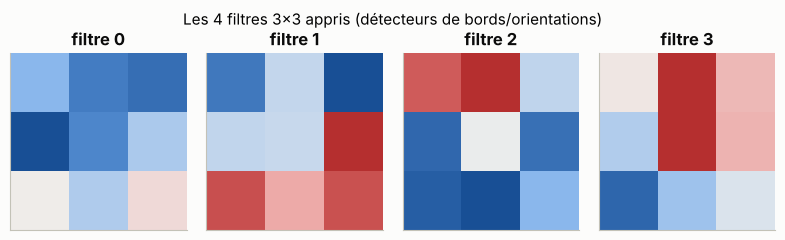

In [15]:
perm = np.random.default_rng(0).permutation(len(yd))
p_conv, _ = train(make_hidden_net("conv"), cols_all[perm[:320]], yd[perm[:320]], epochs=300, batch=64, lr=0.01,
                  grad_fn=hidden_net_loss("conv"))
fig, axes = plt.subplots(1, 4, figsize=(8, 2.4))
for f, ax in enumerate(axes):
    ax.imshow(p_conv[0][0][:, f].reshape(3, 3), cmap="div_blue_red", vmin=-2, vmax=2)
    ax.set_title(f"filtre {f}"); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.suptitle("Les 4 filtres 3×3 appris (détecteurs de bords/orientations)", fontsize=11)
plt.tight_layout(); plt.show()

## Partie 4 — Application : prévoir la volatilité, MLP contre HAR

Le modèle **HAR** (Corsi, 2009) prédit la volatilité future par une régression **linéaire** sur la volatilité réalisée journalière, hebdomadaire et mensuelle — trois horizons qui reflètent des acteurs différents (*day traders*, gérants, investisseurs de long terme). Il est simple, robuste, et difficile à battre. Un MLP peut-il faire mieux en capturant des non-linéarités ?

- cible : $\log$ de la variance réalisée moyenne des 5 prochains jours, $\log\big(\frac15\sum_{k=1}^5 r_{t+k}^2\big)$ ;
- variables : $\log$ des variances réalisées sur 1, 5 et 22 jours (avec un petit plancher pour le log) ;
- découpage : apprentissage 2000–2014, validation 2015–2018 (arrêt précoce, choix de λ), test 2019–2024.

In [16]:
spy, src = tp_data.load_index_returns("SPY", start="2000-01-01")
print("source :", src)
r2 = spy ** 2
eps = 1e-6
feat = pd.DataFrame({"log RV 1j": np.log(r2 + eps), "log RV 5j": np.log(r2.rolling(5).mean() + eps),
                     "log RV 22j": np.log(r2.rolling(22).mean() + eps)})
target = np.log(r2[::-1].rolling(5).mean()[::-1].shift(-1) + eps).rename("cible")
D = pd.concat([feat, target], axis=1).dropna()
tr_, va_, te_ = D.loc[:"2014"], D.loc["2015":"2018"], D.loc["2019":]
mu, sd = tr_.mean(), tr_.std()
Z = lambda df: ((df - mu) / sd)
Xtr_, ytr_ = Z(tr_)[feat.columns].to_numpy(), Z(tr_)[["cible"]].to_numpy()
Xva_, yva_ = Z(va_)[feat.columns].to_numpy(), Z(va_)[["cible"]].to_numpy()
Xte_, yte_ = Z(te_)[feat.columns].to_numpy(), Z(te_)[["cible"]].to_numpy()
print("tailles :", len(tr_), len(va_), len(te_))

[tp_data] SPY_2000_2024 : yfinance indisponible (ModuleNotFoundError) — `pip install yfinance` pour les données réelles ; bascule sur la simulation
[tp_data] SPY_2000_2024 : données SIMULÉES (modèle à facteurs GARCH)
source : simulé
tailles : 3891 1043 1561


### Exercice 4.1 — HAR (OLS) vs MLP régularisé

In [17]:
def oos_r2(y, pred, y_train_mean):
    return 1 - ((y - pred) ** 2).sum() / ((y - y_train_mean) ** 2).sum()

Xi = np.c_[np.ones(len(Xtr_)), Xtr_]
beta_har = np.linalg.lstsq(Xi, ytr_, rcond=None)[0]
pred_har = np.c_[np.ones(len(Xte_)), Xte_] @ beta_har
best = None
for lam in [0.0, 1e-4, 1e-3, 1e-2]:
    p_, h_ = train(init_mlp([3, 16, 1], seed=0), Xtr_, ytr_, task="regression", act="tanh", lam=lam,
                   epochs=300, batch=128, lr=0.003, X_val=Xva_, Y_val=yva_, patience=30)
    vl = np.mean((forward(p_, Xva_, "tanh")[0] - yva_) ** 2)
    if best is None or vl < best[0]:
        best = (vl, lam, p_)
pred_mlp = forward(best[2], Xte_, "tanh")[0]
res = pd.DataFrame({"R² hors échantillon (test 2019–2024)": [oos_r2(yte_, pred_har, ytr_.mean()), oos_r2(yte_, pred_mlp, ytr_.mean())]},
                   index=["HAR (3 coefficients + constante)", f"MLP 3-16-1 (λ = {best[1]})"])
observe(res.iloc[0, 0] > 0.1, "le HAR explique une part notable de la volatilité future")
res

✅ le HAR explique une part notable de la volatilité future


,R² hors échantillon (test 2019–2024)
HAR (3 coefficients + constante),0.1410
MLP 3-16-1 (λ = 0.01),0.1479


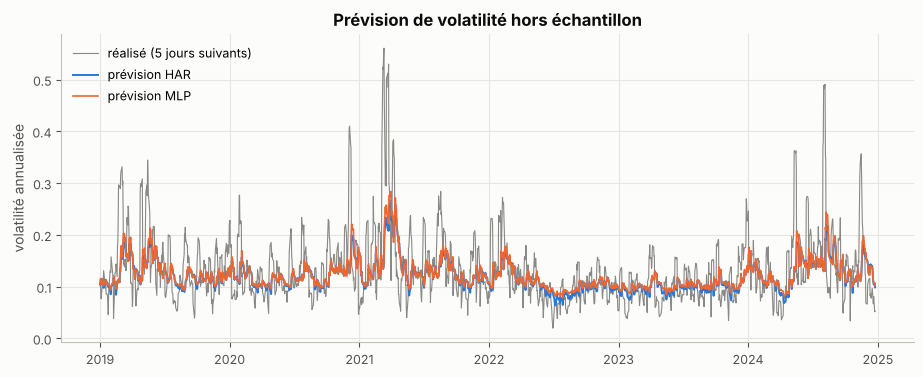

In [18]:
fig, ax = plt.subplots(figsize=(11, 4))
back = lambda z: np.exp(z * sd["cible"] + mu["cible"])
ax.plot(te_.index, np.sqrt(252 * back(yte_[:, 0])), color=GRAY, lw=0.8, label="réalisé (5 jours suivants)")
ax.plot(te_.index, np.sqrt(252 * back(pred_har[:, 0])), color=BLUE, lw=1.4, label="prévision HAR")
ax.plot(te_.index, np.sqrt(252 * back(pred_mlp[:, 0])), color=ORANGE, lw=1.2, label="prévision MLP")
ax.set_ylabel("volatilité annualisée"); ax.set_title("Prévision de volatilité hors échantillon"); ax.legend()
plt.show()

**Questions.**
1. Le MLP bat-il nettement le HAR ? Pourquoi est-ce un résultat attendu ici ?
2. Dans quelles conditions un réseau de neurones a-t-il de bonnes chances d'apporter quelque chose en finance quantitative ?

> **Corrigé.**
>
> 1. Non (au mieux un gain marginal). Avec 3 variables très informatives et une relation presque linéaire en log, le HAR est déjà proche du meilleur prédicteur possible à partir de ces informations ; le MLP n'a pas de structure supplémentaire à découvrir et paie sa flexibilité en variance (d'où la nécessité de l'arrêt précoce et du weight decay). Le rapport signal/bruit d'une variance réalisée sur 5 jours est faible : beaucoup de l'erreur est irréductible.
> 2. Quand il y a **beaucoup de données** et **beaucoup de variables** avec des interactions complexes (carnets d'ordres complets, centaines de caractéristiques en coupe transversale, données alternatives : texte, images), ou une **structure** à exploiter (invariances → convolutions sur séries temporelles ou carnets d'ordres, récurrence, attention). Il faut toujours une référence simple (HAR, ridge, forêt) et une validation temporelle stricte.

## Partie 5 — Synthèse : quel réseau, quand ?

| Modèle | Capacité | Entraînement | Forces | Faiblesses | Quand l'utiliser |
|---|---|---|---|---|---|
| **Perceptron** | frontière linéaire | SGD sur points mal classés | simple, converge en $(R/\gamma)^2$ mises à jour si séparable | ne converge pas sinon (XOR), pas de probabilités, solution non unique | pédagogique ; préférer logistique / SVM |
| **MLP** | approximateur universel | rétropropagation + SGD/Adam | très flexible, s'adapte à toute perte | non convexe (minima locaux), nombreux hyperparamètres, besoin de données, peu interprétable | beaucoup de données, relations non linéaires complexes, variables nombreuses |
| **CNN** | MLP avec connexions locales + poids partagés | idem | invariance par translation, beaucoup moins de paramètres → meilleure généralisation | suppose une structure de grille (image, série temporelle) | images, signaux, séries temporelles, carnets d'ordres |

**Régularisation :**
- **arrêt précoce** — gratuit, toujours utile, nécessite un jeu de validation (temporel en finance) ;
- **weight decay** — équivalent à ridge, λ par validation ;
- **dropout** — moyenne implicite d'un ensemble de sous-réseaux, surtout utile pour les grands réseaux.